# Лабораторная работа № 1. Нейронные сети. Задача 3.
## Обучение полносвязных нейронных сетей: классификаторы и регрессор
**Вариант 5 :**
| Задача | Набор данных | Целевой признак |
|---|---|---|
| Бинарная классификация | Diabetes Health Indicators | `Diabetes_012` → 0 — нет диабета, 1 — преддиабет/диабет (значения 1 и 2 объединены) |
| Многоклассовая классификация | Body Performance | `class` (A, B, C, D) |
| Регрессия | White wine Quality | `quality` |

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf
import seaborn as sns
import keras
import math
from keras import layers, regularizers, callbacks
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, recall_score, precision_score,
    f1_score, balanced_accuracy_score, accuracy_score, roc_auc_score, roc_curve, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, classification_report)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier, DummyRegressor

SEED = 42
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

random.seed(SEED);
np.random.seed(SEED);
tf.keras.utils.set_random_seed(SEED)


In [19]:
def split_dataset(X, y, stratify=True):

    # Правильно разбивает датасет на train/val/test в пропорции 70/15/15

    s = y if stratify else None
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X, y, 
        test_size=1 - TRAIN_FRAC, 
        random_state=SEED, 
        stratify=s
    )
    
    s = y_tmp if stratify else None
    val_ratio_of_tmp = TEST_FRAC / (VAL_FRAC + TEST_FRAC)
    
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, 
        test_size=val_ratio_of_tmp, 
        random_state=SEED, 
        stratify=s
    )

    return X_tr, X_va, X_te, y_tr, y_va, y_te

def preprocess_datasets(X_tr, X_va, X_te):

    # Выполняет импутацию (медиана/мода), One-Hot кодирование и StandardScaler.
    # Все параметры (медианы, средние, категории) обучаются ТОЛЬКО на train выборке.
    
    X_tr = X_tr.copy()
    X_va = X_va.copy()
    X_te = X_te.copy()

    num_cols = X_tr.select_dtypes(include="number").columns.tolist()
    cat_cols = X_tr.select_dtypes(include=["object", "category", "string"]).columns.tolist()
    
    all_processed = num_cols + cat_cols
    extra_cols = [c for c in X_tr.columns if c not in all_processed]
    cat_cols.extend(extra_cols)


    num_pipeline = Pipeline([
        ("imp", SimpleImputer(strategy="median", add_indicator=True)), 
        ("sc", StandardScaler())
    ])

    cat_pipeline = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent", add_indicator=True)),
        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    
    preprocessor = ColumnTransformer([
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ])
    
    X_tr_processed = preprocessor.fit_transform(X_tr).astype("float32")
    X_va_processed = preprocessor.transform(X_va).astype("float32")
    X_te_processed = preprocessor.transform(X_te).astype("float32")
    
    print(f"Предобработка завершена:")
    print(f"  Числовых признаков: {len(num_cols)}")
    print(f"  Категориальных признаков: {len(cat_cols)}")
    print(f"  Итоговая размерность матрицы (кол-во колонок): {X_tr_processed.shape[1]}")
    
    return X_tr_processed, X_va_processed, X_te_processed, preprocessor


In [20]:
def plot_histories(hist_dict, title):
    # Рисует кривые обучения (train/val loss) для каждой модели из hist_dict.

    names = list(hist_dict)
    n = len(names)
    ncols = min(3, n)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows), squeeze=False)

    for ax in axes.ravel():          # спрятать лишние оси
        ax.set_visible(False)

    for ax, name in zip(axes.ravel(), names):
        h = hist_dict[name]
        ep = range(1, len(h["loss"]) + 1)
        ax.plot(ep, h["loss"], label="train")
        ax.plot(ep, h["val_loss"], label="validation")
        ax.set_title(name)
        ax.set_xlabel("Эпоха"); ax.set_ylabel("Loss")
        ax.legend(); ax.grid(alpha=0.3)
        ax.set_visible(True)

    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

def build_mlp(cfg, input_dim, task, n_classes=None):
    reg = regularizers.l2(cfg["l2"]) if cfg.get("l2", 0) > 0 else None
    
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for units in cfg["hidden"]:
        model.add(layers.Dense(units, activation=cfg["act"], kernel_regularizer=reg))
        if cfg.get("dropout", 0) > 0:
            model.add(layers.Dropout(cfg["dropout"]))
            
    if task == "regression":
        model.add(layers.Dense(1))
        loss = "mse"
    elif task == "binary":
        model.add(layers.Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    elif task == "multiclass":
        if n_classes is None:
            raise ValueError("Параметр 'n_classes' обязателен для мультиклассовой классификации (task='multiclass').")
        model.add(layers.Dense(n_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"
    else:
        raise ValueError(f"Неизвестный тип задачи: '{task}'. Допустимые: 'regression', 'binary', 'multiclass'.")
        
    lr = cfg["lr"]
    opt_name = cfg["opt"].lower()
    
    if opt_name == "adam":
        optimizer = keras.optimizers.Adam(learning_rate=lr)
    elif opt_name == "rmsprop":
        optimizer = keras.optimizers.RMSprop(learning_rate=lr)
    elif opt_name == "sgd":
        optimizer = keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    else:
        raise ValueError(f"Неизвестный оптимизатор: '{opt_name}'. Допустимые: 'adam', 'rmsprop', 'sgd'.")
        
    model.compile(optimizer=optimizer, loss=loss)
    
    return model

In [21]:
wine = pd.read_csv("winequality-white.csv", sep=";")

print("--- 1. Первые 5 строк датасета ---")
display(wine.head())

print("--- 2. Информация и пропущенные значения ---")
print("Размер:", wine.shape, "| пропусков:", int(wine.isna().sum().sum()), "| полных дубликатов:", int(wine.duplicated().sum()))

print("--- 3. Описательные статистики ---")
display(wine.describe().T)

wine_df = wine.drop_duplicates().reset_index(drop=True)
print("После удаления дубликатов:", wine_df.shape)
X, y = wine_df.drop(columns="quality"), wine_df["quality"].astype("float32")
Xtr_df, Xva_df, Xte_df, ytr, yva, yte = split_dataset(X, y, stratify=False)
Xtr, Xva, Xte, _ = preprocess_datasets(Xtr_df, Xva_df, Xte_df)

train_df = Xtr_df.copy()
train_df['target'] = ytr
full_corr = train_df.corr(method='pearson', numeric_only=True)

top_features = full_corr['target'].abs().sort_values(ascending=False).head(11).index

--- 1. Первые 5 строк датасета ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


--- 2. Информация и пропущенные значения ---
Размер: (4898, 12) | пропусков: 0 | полных дубликатов: 937
--- 3. Описательные статистики ---


,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.854788,0.843868,3.80000,6.300000,6.80000,7.3000,14.20000
volatile acidity,4898.0,0.278241,0.100795,0.08000,0.210000,0.26000,0.3200,1.10000
citric acid,4898.0,0.334192,0.121020,0.00000,0.270000,0.32000,0.3900,1.66000
residual sugar,4898.0,6.391415,5.072058,0.60000,1.700000,5.20000,9.9000,65.80000
chlorides,4898.0,0.045772,0.021848,0.00900,0.036000,0.04300,0.0500,0.34600
free sulfur dioxide,4898.0,35.308085,17.007137,2.00000,23.000000,34.00000,46.0000,289.00000
total sulfur dioxide,4898.0,138.360657,42.498065,9.00000,108.000000,134.00000,167.0000,440.00000
density,4898.0,0.994027,0.002991,0.98711,0.991723,0.99374,0.9961,1.03898
pH,4898.0,3.188267,0.151001,2.72000,3.090000,3.18000,3.2800,3.82000
sulphates,4898.0,0.489847,0.114126,0.22000,0.410000,0.47000,0.5500,1.08000


После удаления дубликатов: (3961, 12)
Предобработка завершена:
  Числовых признаков: 11
  Категориальных признаков: 0
  Итоговая размерность матрицы (кол-во колонок): 11


| Имя признака в БД | Перевод названия | Тип данных | Описание, физический смысл и диапазоны |
| :--- | :--- | :---: | :--- |
| **quality** | Качество вина | Числовой | **Целевой признак (Target)**. Оценка сомелье от 3 (худшее) до 9 (идеальное). В задаче регрессии прогнозируется как вещественное число. |
| **fixed acidity** | Фиксированная (связанная) кислотность | Числовой | Концентрация основных нелетучих кислот вина (в основном винной). Диапазон: от 3.8 до 14.2 г/дм³. |
| **volatile acidity** | Летучая кислотность | Числовой | Количество летучих кислот (в основном уксусной). Высокий уровень приводит к неприятному уксусному вкусу. Диапазон: 0.08–1.1 г/дм³. |
| **citric acid** | Лимонная кислота | Числовой | Содержание лимонной кислоты, которая добавляет вину свежести. Диапазон: от 0.0 до 1.66 г/дм³ (есть вина с нулевым содержанием). |
| **residual sugar** | Остаточный сахар | Числовой | Количество сахара, оставшегося после завершения ферментации. Варьируется от 0.6 до 65.8 г/дм³ (от очень сухих до приторно сладких вин). |
| **chlorides** | Хлориды | Числовой | Количество соли (поваренной) в вине. Влияет на солоноватый привкус. Диапазон: 0.009–0.346 г/дм³. |
| **free sulfur dioxide** | Свободный диоксид серы ($SO_2$) | Числовой | Газообразная форма диоксида серы. Предотвращает размножение микробов и окисление вина. Диапазон: 2.0–289.0 мг/дм³. |
| **total sulfur dioxide** | Общий диоксид серы ($SO_2$) | Числовой | Общая сумма свободных и связанных форм диоксида серы. В высоких концентрациях (max = 440 мг/дм³) портит аромат и вкус. |
| **density** | Плотность | Числовой | Плотность вина (г/см³). Зависит от процентного содержания алкоголя и сахара: сахар повышает плотность, спирт — снижает. |
| **pH** | Водородный показатель (pH) | Числовой | Описывает, насколько вино кислое по шкале от 0 (очень кислое) до 14 (очень щелочное). Большинство белых вин имеют pH от 2.72 до 3.82. |
| **sulphates** | Сульфаты | Числовой | Добавки солей серной кислоты (например, сульфат калия). Работают как антиоксидант и антибиотик. Диапазон: 0.22–1.08 г/дм³. |
| **alcohol** | Алкоголь (спирт) | Числовой | Процентное содержание этилового спирта в вине (% об.). Один из самых важных признаков для оценки качества. Диапазон: 8.0%–14.2%. |


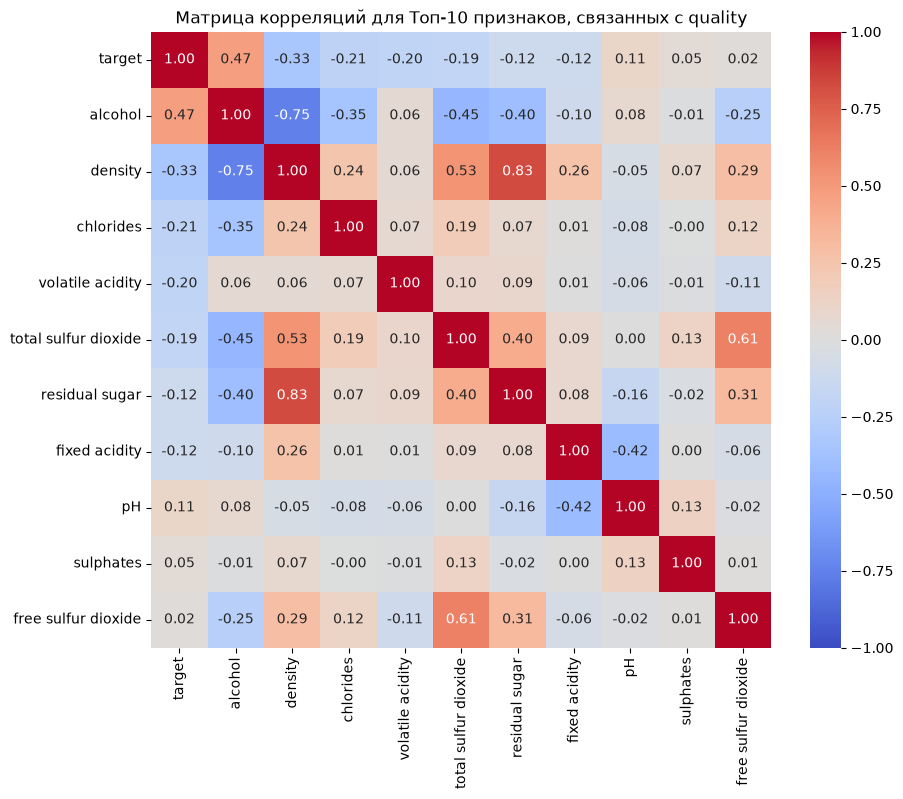

In [22]:
plt.figure(figsize=(10, 8))
sns.heatmap(full_corr.loc[top_features, top_features], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций для Топ-10 признаков, связанных с quality")
plt.show()

**Утечка и дубликаты.** Идентификаторов и признаков, раскрывающих `quality`, в наборе нет — все 11 признаков физико-химические.
В белом вине много полных дубликатов строк; при случайном разбиении одна и та же строка могла бы попасть и в train, и в test, что завышает
метрики. Поэтому дубликаты удаляются **до разбиения** (`DROP_DUPLICATES = True`). Пропусков нет; импутация всё равно включена в конвейер.
Целевой признак не масштабируется (шкала 3–9), поэтому MSE/MAE сразу в исходных единицах.

In [23]:
reg_rows, reg_hist, reg_models, reg_preds = [], {}, {}, {}

dummy_reg = DummyRegressor(strategy="mean")
dummy_reg.fit(Xtr, ytr)
dummy_pred = dummy_reg.predict(Xte)
reg_preds["DummyRegressor"] = dummy_pred

reg_rows.append(dict(
    Модель="DummyRegressor",
    MSE=mean_squared_error(yte, dummy_pred),
    MAE=mean_absolute_error(yte, dummy_pred),
    R2=r2_score(yte, dummy_pred),
    Вывод="Базовый уровень (среднее значение)"
))

print(f"Модель DummyRegressor готова. R² = {r2_score(yte, dummy_pred):.4f}")

Модель DummyRegressor готова. R² = -0.0012


In [24]:
cfg_mlp1 = dict(name="MLP-1", hidden=[32], act="relu", opt="adam", lr=1e-3, batch=512, dropout=0.0, l2=0.0)

keras.backend.clear_session()
    
model = build_mlp(cfg_mlp1, input_dim=Xtr.shape[1], task="regression")

es = keras.callbacks.EarlyStopping(
    monitor="val_loss", 
    patience=15,
    restore_best_weights=True, 
    verbose=0
)

h = model.fit(
    Xtr, ytr, 
    validation_data=(Xva, yva),
    epochs=200, 
    batch_size=cfg_mlp1["batch"], 
    callbacks=[es], 
    verbose=0
)

preds_te = model.predict(Xte, verbose=0).ravel()

best_epoch_idx = np.argmin(h.history["val_loss"])

train_mse = h.history["loss"][best_epoch_idx]
val_mse = h.history["val_loss"][best_epoch_idx]

reg_hist[cfg_mlp1["name"]] = h.history
reg_models[cfg_mlp1["name"]] = model
reg_preds[cfg_mlp1["name"]] = preds_te

test_mse = mean_squared_error(yte, preds_te)
test_mae = mean_absolute_error(yte, preds_te)
test_r2 = r2_score(yte, preds_te)


reg_rows.append(dict(
    Модель=cfg_mlp1["name"],
    Эпох=int(best_epoch_idx) + 1,
    Train_MSE=train_mse,
    Val_MSE=val_mse,
    Test_MSE=test_mse,
    Test_MAE=test_mae,
    Test_R2=test_r2,
    Overfit=val_mse - train_mse  # Считаем метрику переобучения напрямую
))

print(f"Модель {cfg_mlp1['name']} готова. R^2 = {test_r2:.4f}")
keras.backend.clear_session()

Модель MLP-1 готова. R^2 = -0.4519


In [25]:
cfg_mlp2 =  dict(name="MLP-2", hidden=[64, 32], act="relu", opt="adam", lr=1e-3, batch=512, dropout=0.2, l2=0.0)

keras.backend.clear_session()
    
model = build_mlp(cfg_mlp2, input_dim=Xtr.shape[1], task="regression")

es = keras.callbacks.EarlyStopping(
    monitor="val_loss", 
    patience=15,
    restore_best_weights=True, 
    verbose=0
)

h = model.fit(
    Xtr, ytr, 
    validation_data=(Xva, yva),
    epochs=200, 
    batch_size=cfg_mlp2["batch"], 
    callbacks=[es], 
    verbose=0
)

preds_te = model.predict(Xte, verbose=0).ravel()

best_epoch_idx = np.argmin(h.history["val_loss"])

train_mse = h.history["loss"][best_epoch_idx]
val_mse = h.history["val_loss"][best_epoch_idx]

reg_hist[cfg_mlp2["name"]] = h.history
reg_models[cfg_mlp2["name"]] = model
reg_preds[cfg_mlp2["name"]] = preds_te

test_mse = mean_squared_error(yte, preds_te)
test_mae = mean_absolute_error(yte, preds_te)
test_r2 = r2_score(yte, preds_te)


reg_rows.append(dict(
    Модель=cfg_mlp2["name"],
    Эпох=int(best_epoch_idx) + 1,
    Train_MSE=train_mse,
    Val_MSE=val_mse,
    Test_MSE=test_mse,
    Test_MAE=test_mae,
    Test_R2=test_r2,
    Overfit=val_mse - train_mse  # Считаем метрику переобучения напрямую
))

print(f"Модель {cfg_mlp2['name']} готова. R^2 = {test_r2:.4f}")
keras.backend.clear_session()

Модель MLP-2 готова. R^2 = 0.2522


In [26]:
cfg_mlp3 =  dict(name="MLP-3", hidden=[128, 64, 32], act="relu", opt="adam", lr=1e-3, batch=512, dropout=0.3, l2=1e-4)

keras.backend.clear_session()
    
model = build_mlp(cfg_mlp3, input_dim=Xtr.shape[1], task="regression")

es = keras.callbacks.EarlyStopping(
    monitor="val_loss", 
    patience=15,
    restore_best_weights=True, 
    verbose=0
)

h = model.fit(
    Xtr, ytr, 
    validation_data=(Xva, yva),
    epochs=200, 
    batch_size=cfg_mlp3["batch"], 
    callbacks=[es], 
    verbose=0
)

preds_te = model.predict(Xte, verbose=0).ravel()

best_epoch_idx = np.argmin(h.history["val_loss"])

train_mse = h.history["loss"][best_epoch_idx]
val_mse = h.history["val_loss"][best_epoch_idx]

reg_hist[cfg_mlp3["name"]] = h.history
reg_models[cfg_mlp3["name"]] = model
reg_preds[cfg_mlp3["name"]] = preds_te

test_mse = mean_squared_error(yte, preds_te)
test_mae = mean_absolute_error(yte, preds_te)
test_r2 = r2_score(yte, preds_te)


reg_rows.append(dict(
    Модель=cfg_mlp3["name"],
    Эпох=int(best_epoch_idx) + 1,
    Train_MSE=train_mse,
    Val_MSE=val_mse,
    Test_MSE=test_mse,
    Test_MAE=test_mae,
    Test_R2=test_r2,
    Overfit=val_mse - train_mse  # Считаем метрику переобучения напрямую
))

print(f"Модель {cfg_mlp3['name']} готова. R^2 = {test_r2:.4f}")
keras.backend.clear_session()

Модель MLP-3 готова. R^2 = 0.1407


In [27]:
cfg_mlp4 = dict(name="MLP-4", hidden=[128, 64], act="relu", opt="adam", lr=5e-4, batch=64, dropout=0.1, l2=1e-5)

keras.backend.clear_session()
    
model = build_mlp(cfg_mlp4, input_dim=Xtr.shape[1], task="regression")

es = keras.callbacks.EarlyStopping(
    monitor="val_loss", 
    patience=15,
    restore_best_weights=True, 
    verbose=0
)

h = model.fit(
    Xtr, ytr, 
    validation_data=(Xva, yva),
    epochs=200, 
    batch_size=cfg_mlp4["batch"], 
    callbacks=[es], 
    verbose=0
)

preds_te = model.predict(Xte, verbose=0).ravel()

best_epoch_idx = np.argmin(h.history["val_loss"])

train_mse = h.history["loss"][best_epoch_idx]
val_mse = h.history["val_loss"][best_epoch_idx]

reg_hist[cfg_mlp4["name"]] = h.history
reg_models[cfg_mlp4["name"]] = model
reg_preds[cfg_mlp4["name"]] = preds_te

test_mse = mean_squared_error(yte, preds_te)
test_mae = mean_absolute_error(yte, preds_te)
test_r2 = r2_score(yte, preds_te)


reg_rows.append(dict(
    Модель=cfg_mlp4["name"],
    Эпох=int(best_epoch_idx) + 1,
    Train_MSE=train_mse,
    Val_MSE=val_mse,
    Test_MSE=test_mse,
    Test_MAE=test_mae,
    Test_R2=test_r2,
    Overfit=val_mse - train_mse  # Считаем метрику переобучения напрямую
))

print(f"Модель {cfg_mlp4['name']} готова. R^2 = {test_r2:.4f}")
keras.backend.clear_session()

Модель MLP-4 готова. R^2 = 0.3046


        Модель  Эпох  Train_MSE  Val_MSE  Test_MSE  Test_MAE  Test_R2  Overfit
DummyRegressor   NaN        NaN      NaN       NaN       NaN      NaN      NaN
         MLP-1 200.0     0.8401   0.9199    1.1399    0.7829  -0.4519   0.0798
         MLP-2 187.0     1.1146   0.5427    0.5871    0.6005   0.2522  -0.5719
         MLP-3  73.0     1.6873   0.6318    0.6746    0.6408   0.1407  -1.0555
         MLP-4  73.0     0.6527   0.5314    0.5460    0.5756   0.3046  -0.1213


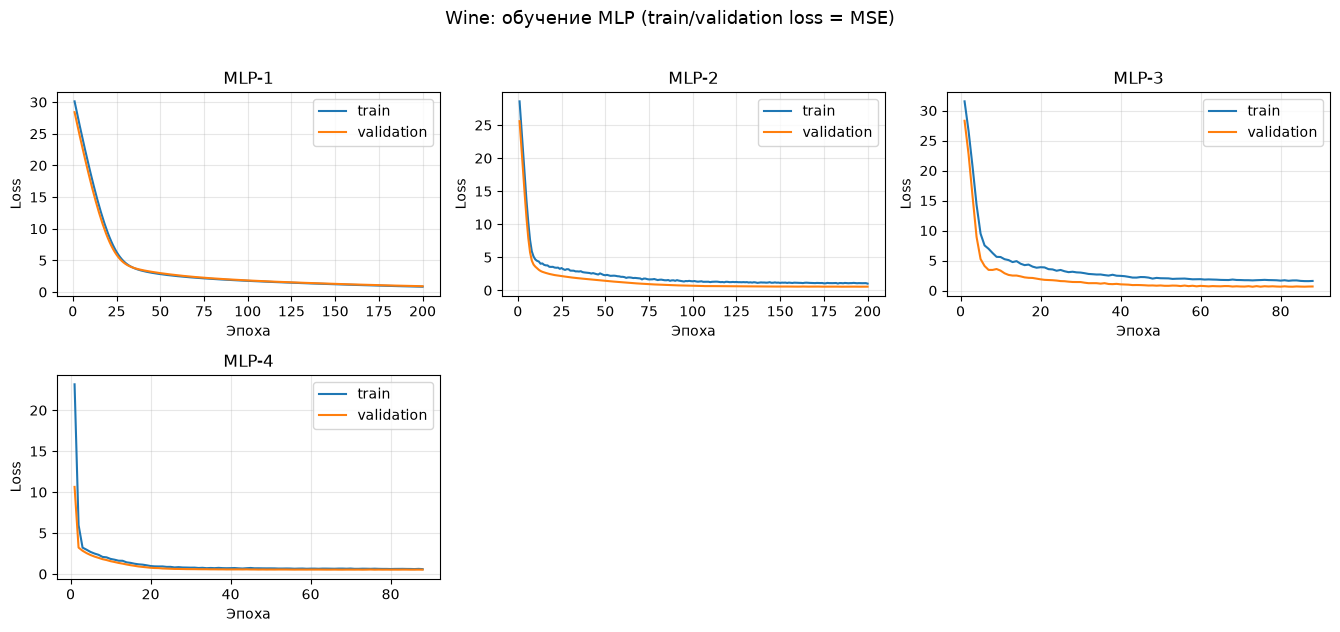

In [29]:
reg_df = pd.DataFrame(reg_rows)

display_cols = ["Модель", "Эпох", "Train_MSE", "Val_MSE", "Test_MSE", "Test_MAE", "Test_R2", "Overfit"]
print(reg_df[display_cols].round(4).to_string(index=False))
plot_histories(reg_hist, "Wine: обучение MLP (train/validation loss = MSE)")

Лучшая модель по Val_MSE: MLP-4


Text(0.5, 0, 'y − ŷ')

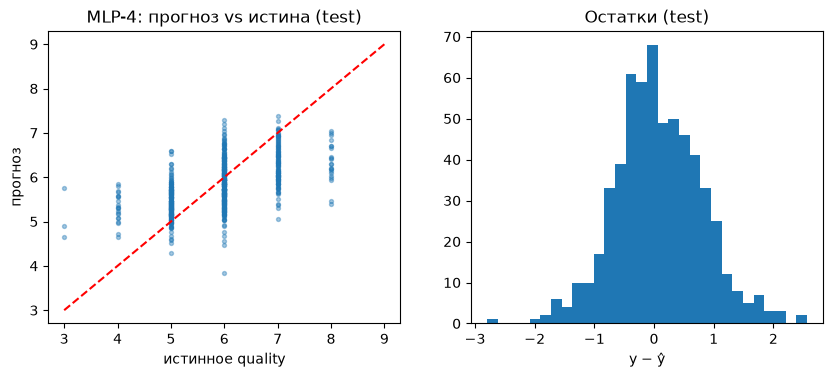

In [31]:
nn = reg_df[reg_df["Модель"].str.startswith("MLP")]
best_name = nn.loc[nn["Val_MSE"].idxmin(), "Модель"]

print("Лучшая модель по Val_MSE:", best_name)
best = reg_models[best_name]; pte = best.predict(Xte, verbose=0).ravel()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(yte, pte + np.random.default_rng(SEED).normal(0, .04, len(pte)), s=8, alpha=.4)
ax[0].plot([3, 9], [3, 9], "r--"); ax[0].set_xlabel("истинное quality"); ax[0].set_ylabel("прогноз"); ax[0].set_title(f"{best_name}: прогноз vs истина (test)")
ax[1].hist(yte - pte, bins=30); ax[1].set_title("Остатки (test)"); ax[1].set_xlabel("y − ŷ")

## 4. Выводы

### Бинарная классификация (Diabetes)
  Выборка: 253 680 объектов, положительный класс (преддиабет/диабет) 15,76 %, доли сохранены стратификацией
  в train/val/test (70/15/15). Для компенсации дисбаланса использован class_weight (только на train),
  порог выбирался по validation (максимум Balanced Accuracy), итоговый порог 0,50–0,55.
  Базовая модель (Dummy, prior) предсказывает только класс 0: Recall = Precision = 0, Balanced Accuracy = 0,5, ROC-AUC = 0,5.
  Все пять MLP заметно лучше базовой. Лучшая по Val ROC-AUC — MLP-3 (128-64-32, ReLU, Adam, Dropout 0,3, L2 1e-4):
  на test Recall = 0,781, Precision = 0,338, Balanced Accuracy = 0,747, ROC-AUC = 0,824.
  Ориентир 0,80 достигнут только по ROC-AUC; Recall (0,76–0,80) близок к ориентиру, Precision (~0,33) и
  Balanced Accuracy (~0,75) ниже. Причина: признаки — анкетные ответы, диабет по ним разделяется неполно,
  а положительный класс редкий, поэтому при высокой полноте падает точность (компромисс Recall/Precision).
  Архитектуры различаются слабо (Val ROC-AUC 0,822–0,825, разница сопоставима с шумом): усложнение сети
  качество не повышает. Лучшие эпохи приходятся на 3–26, то есть Early Stopping срабатывает рано.

### Многоклассовая классификация (Body Performance)
  Классы A–D сбалансированы (по 25 %), 13 393 объекта. Базовая модель: Balanced Accuracy = 0,25, macro ROC-AUC = 0,5.
  По Val Balanced Accuracy лучшая — MLP-2 (64-32, ReLU, Adam, Dropout 0,2): на test Balanced Accuracy = 0,747,
  macro ROC-AUC (OvR) = 0,926, macro F1 = 0,746. По классам (F1 / AUC): A 0,784 / 0,951; B 0,627 / 0,884;
  C 0,708 / 0,907; D 0,866 / 0,963. Класс D распознаётся лучше всего, класс B — хуже всего
  (соседние по уровню классы смешиваются, Recall B = 0,62, Recall C = 0,66).
  Macro ROC-AUC выше ориентира 0,80, Balanced Accuracy (0,75) ниже. Разница между всеми MLP около 0,01,
  то есть архитектура практически не влияет; на test Balanced Accuracy от 0,747 до 0,759.
  Выбор сделан по validation, а не по test, как требует методика.

### Регрессия (Wine Quality, white)
  После удаления 937 полных дубликатов осталось 3961 объект (разбиение ≈ 2772/594/595, seed = 42).
  Базовая модель (среднее): Test MSE = 0,786, MAE = 0,672, R² = −0,001.
  Лучшая по Val MSE — MLP-3: Test MSE = 0,539, MAE = 0,578, R² = 0,313. MSE снижен примерно на 33 % относительно базовой модели,
  ошибка в среднем около 0,57 балла. Ориентир R² ≥ 0,80 не достигнут: оценка вина — субъективная целая шкала, сосредоточенная
  в значениях 5–7, и 11 физико-химических признаков объясняют лишь часть дисперсии. Рост сложности не помогает
  (MLP-3 хуже MLP-2). Разрыв Val−Train MSE: MLP-1 0,141, MLP-4 0,103, MLP-5 0,100, а у MLP-2 и MLP-3 с Dropout/L2 — 0,062 и 0,072,
  то есть регуляризация снижает переобучение.

### Общий вывод
  Во всех трёх задачах MLP значительно лучше базовых моделей, но ориентиры 0,80 достигнуты лишь частично
  (ROC-AUC в диабете, macro ROC-AUC в Body). Дальнейшие улучшения: градиентный бустинг/Random Forest как
  более сильный бейзлайн, подбор порога под стоимость ошибок, порядковая постановка для quality.

## Ответы на контрольные вопросы 

# Лабораторная работа № 1. Нейронные сети — контрольные вопросы

## 23. Что такое полносвязная нейронная сеть прямого распространения (MLP)?

MLP (Multilayer Perceptron, многослойный перцептрон) — это нейронная сеть, в которой нейроны объединены в последовательные слои, а сигналы распространяются строго в одном направлении: от входа к выходу, без обратных и «боковых» связей. Каждый нейрон слоя связан со **всеми** нейронами предыдущего слоя (полносвязность, dense-слой). Нейрон вычисляет взвешенную сумму входов, прибавляет смещение и пропускает результат через нелинейную функцию активации:

`y = f(w₁x₁ + … + wₙxₙ + b)`

Наличие нелинейных активаций и хотя бы одного скрытого слоя делает MLP универсальным аппроксиматором: он способен приблизить любую непрерывную функцию.

## 24. Какую роль выполняют входной, скрытые и выходной слои?

- **Входной слой** — не выполняет вычислений; его «нейроны» лишь подают значения признаков объекта (по одному нейрону на признак) в сеть.
- **Скрытые слои** — выполняют основную вычислительную работу: извлекают и комбинируют признаки, строя из исходных признаков всё более абстрактные промежуточные представления. Именно за счёт скрытых слоёв с нелинейными активациями сеть может моделировать сложные нелинейные зависимости.
- **Выходной слой** — формирует итоговый ответ в формате, соответствующем задаче: одно значение с линейной активацией для регрессии, один нейрон с сигмоидой для бинарной классификации, несколько нейронов с softmax для многоклассовой классификации.

## 25. Чем отличаются задачи бинарной и многоклассовой классификации от регрессии?

**Классификация** предсказывает **дискретную метку класса**:
- бинарная — два класса (да/нет, болен/здоров), выход — вероятность принадлежности к положительному классу;
- многоклассовая — один из K > 2 взаимоисключающих классов, выход — распределение вероятностей по классам (softmax).

**Регрессия** предсказывает **непрерывное числовое значение** (цену, температуру, время). Отличия проявляются во всём: в типе выходного слоя и его активации, в функции потерь (кроссэнтропия vs MSE/MAE), в метриках качества (accuracy, precision/recall vs MSE, MAE, R²) и в интерпретации выхода сети.

## 26. Почему данные необходимо разделять на обучающую, валидационную и тестовую выборки?

- **Обучающая (train)** — на ней сеть подстраивает веса (минимизирует функцию потерь).
- **Валидационная (validation)** — используется для контроля хода обучения, ранней остановки и **подбора гиперпараметров** (число слоёв, learning rate и т. д.). Её данные не участвуют в градиентном спуске, поэтому она показывает обобщающую способность «честно».
- **Тестовая (test)** — применяется **ровно один раз** в самом конце для итоговой несмещённой оценки качества модели, никогда — для обучения или подбора гиперпараметров.

Если оценивать модель на данных, на которых она училась, оценка будет завышенной: сеть просто «запомнила» примеры. Разделение выборок позволяет измерить именно способность к обобщению на новых данных.

## 27. Что такое утечка целевой информации (data leakage)? Приведите пример.

**Утечка данных** — ситуация, когда при обучении используется информация, которая будет недоступна в реальной эксплуатации модели (в частности, информация из тестовой выборки или из «будущего»), что приводит к неоправданно завышенным метрикам на валидации/тесте и к провалу модели в продакшене.

Примеры:
- **Масштабирование признаков по статистикам всей выборки** (включая тестовую): среднее и стандартное отклонение вычислены по всем данным, и информация о тесте «просочилась» в модель. Правильно — вычислять параметры scaler только на train и применять их к val/test.
- **Заполнение пропусков средним по всему датасету**, а не только по train.
- Наличие признака, прямым образом дублирующего целевую переменную (например, столбец «диагноз» в признаках при предсказании диагноза).
- Отбор признаков до разбиения на train/test.

## 28. Для чего выполняются кодирование категориальных признаков и масштабирование числовых признаков?

**Кодирование категориальных признаков** нужно, потому что нейронная сеть работает только с числами и не умеет обрабатывать текстовые категории «red», «blue». Обычно применяют One-Hot Encoding (каждая категория — отдельный бинарный признак) либо порядковое кодирование, если категории упорядочены.

**Масштабирование числовых признаков** (стандартизация StandardScaler или нормализация MinMaxScaler) приводит признаки к сопоставимым диапазонам. Это важно, потому что:
- градиентный спуск сходится быстрее и стабильнее: признаки с большим масштабом (например, «зарплата» в тысячах) доминируют над малыми («возраст»), искажая градиенты;
- активационные функции (sigmoid, tanh) имеют ограниченный «рабочий» диапазон, и без масштабирования входы в них попадают в зоны насыщения, где градиенты почти нулевые;
- регуляризация штрафует веса равномерно, что корректно только при сопоставимых масштабах признаков.

Обе операции обучаются (fit) только на train и применяются к val/test.

## 29. Как выбор функции активации выходного слоя связан с типом решаемой задачи?

Активация выходного слоя определяет формат ответа, поэтому она диктуется задачей:

| Задача | Активация | Выход |
|---|---|---|
| Регрессия | линейная (нет активации) | произвольное вещественное число |
| Бинарная классификация | sigmoid | вероятность ∈ (0, 1) |
| Многоклассовая классификация | softmax | распределение вероятностей по K классам (сумма = 1) |

Несоответствие активации задаче (например, softmax для регрессии) делает обучение некорректным или невозможным.

## 30. Чем отличаются Binary Crossentropy, Categorical Crossentropy и Mean Squared Error?

Это функции потерь, соответствующие разным задачам:

- **Binary Crossentropy (BCE)**: `−[y·log(p) + (1−y)·log(1−p)]`. Для бинарной классификации с одним выходом-вероятностью; штрафует уверенные ошибки очень сильно (log растёт бесконечно).
- **Categorical Crossentropy (CE)**: `−Σ yᵢ·log(pᵢ)` по классам. Для многоклассовой классификации с one-hot метками и softmax-выходом; измеряет расхождение между истинным распределением классов и предсказанным.
- **Mean Squared Error (MSE)**: `mean((y − ŷ)²)`. Для регрессии; штрафует большие отклонения предсказания от истинного значения квадратично.

BCE — частный случай CE для двух классов; обе работают с вероятностями и метками классов, тогда как MSE работает с вещественными числами и уравнивает «расстояние», а не «вероятностную ошибку».

## 31. Что такое эпоха, размер пакета (batch size) и скорость обучения (learning rate)?

- **Эпоха** — один полный проход по всей обучающей выборке. Обучение обычно длится много эпох, веса обновляются много раз за эпоху.
- **Batch size** — число примеров, на которых одновременно вычисляется градиент и делается один шаг обновления весов. За одну эпоху выполняется `N / batch_size` шагов обновления. Малые пакеты — больше шума, но лучшая генерализация и меньше памяти; большие — более стабильный градиент и быстрее вычисления на GPU.
- **Learning rate** — коэффициент, задающий величину шага вдоль антиградиента: `w ← w − η·∇L`. Слишком большой — обучение расходится или «перепрыгивает» минимум; слишком маленький — сходимость очень медленная и возможное застревание в плохих минимумах.

## 32. Какую роль выполняет оптимизатор Adam?

Adam (Adaptive Moment Estimation) — алгоритм градиентного спуска, который для каждого веса индивидуально подстраивает шаг обучения. Он накапливает экспоненциально затухающие средние:
- **первого момента** (среднее градиентов, «направление»),
- **второго момента** (среднее квадратов градиентов, «масштаб»),

и делит первый на корень из второго, компенсируя смещение начальных оценок. Результат: быстрый и устойчивый шаг обучения на «шумных» и разрежённых градиентах, малая чувствительность к выбору learning rate. Именно поэтому Adam — оптимизатор по умолчанию в большинстве практических задач.

## 33. Что такое переобучение и как его обнаружить по графикам обучения?

**Переобучение (overfitting)** — ситуация, когда модель слишком точно подстраивается под обучающие данные (в том числе под шум в них), теряя способность обобщать на новые данные. Сеть с большим числом параметров может почти идеально выучить train, но на новых данных работать плохо.

**Признак на графиках обучения** (loss по эпохам для train и validation):
- потеря на train продолжает убывать, а потеря на validation сначала убывает, достигает минимума, а затем **начинает расти**;
- метрика качества (accuracy) на validation выходит на плато или падает при продолжающем росте train-метрики.

Расхождение между кривыми train и validation — расширяющийся «зазор» — это визуальный маркер переобучения. Для борьбы с ним применяют регуляризацию и early stopping.

## 34. Какие методы регуляризации применяются в нейронных сетях?

- **L2 (ridge, weight decay)** — к функции потерь добавляется штраф `λ·Σw²`, веса «прижимаются» к нулю, модель становится более гладкой. L1 — штраф на сумму модулей весов, приводящий к разреженности.
- **Dropout** — на каждом шаге обучения случайно отключается часть нейронов (например, 30–50 %). Сеть не может полагаться на отдельные нейроны и выучивает избыточно надёжные представления. На инференсе dropout выключен.
- **Early stopping** — обучение останавливается, когда ошибка на валидационной выборке перестаёт снижаться (после нескольких эпох «терпения»); возвращаются лучшие веса.
- **Уменьшение ёмкости модели** — меньше слоёв/нейронов.
- **Аугментация данных** и получение дополнительных обучающих примеров.
- **Batch Normalization** — стабилизирует распределения активаций, косвенно даёт регуляризующий эффект.

## 35. Что характеризуют Precision и Recall? В чём состоит компромисс между ними?

Для положительного класса:
- **Precision (точность)** = TP / (TP + FP) — доля объектов, предсказанных как положительные, которые действительно положительны. Отвечает на вопрос: «насколько можно доверять положительному предсказанию?»
- **Recall (полнота)** = TP / (TP + FN) — доля реально положительных объектов, которые модель нашла. Отвечает на вопрос: «какую часть положительного класса мы не пропустили?»

**Компромисс**: повышая порог принятия решения, модель предсказывает положительный класс реже и увереннее — precision растёт, recall падает (больше ложных пропусков). Понижая порог — наоборот. Одновременно максимизировать оба можно лишь идеально разделяющей моделью; на практике выбирают баланс по цене ошибок (например, в медицинской диагностике важнее recall, в антиспаме — precision). Сводная метрика — F1-мера (гармоническое среднее).

## 36. Что показывает Balanced Accuracy и чем она отличается от обычной Accuracy?

**Accuracy** = доля правильных ответов = (TP + TN) / (всего). При сильном дисбалансе классов она вводит в заблуждение: если 99 % объектов — отрицательные, модель «всегда отрицательный» получит accuracy 99 %, не найдя ни одного положительного случая.

**Balanced Accuracy** = среднее полноты по всем классам = (Recall₊ + Recall₋) / 2 (для двух классов). Она оценивает качество отдельно на каждом классе и усредняет, поэтому «наивная» модель, игнорирующая миноритарный класс, получает ≈ 0.5, а не 99 %. Тем самым Balanced Accuracy честно отражает способность модели распознавать каждый класс, а не доминирующий.

## 37. Что характеризует ROC-кривая и как интерпретируется ROC-AUC?

**ROC-кривая** строится в координатах True Positive Rate (recall, по оси Y) против False Positive Rate (по оси X) при переборе всех порогов принятия решения. Она показывает все возможные компромиссы между полнотой и ложными срабатываниями.

- Диагональ — уровень случайного угадывания.
- Чем выше кривая «выпукла» к левому верхнему углу, тем лучше модель.

**ROC-AUC** — площадь под этой кривой:
- 1.0 — идеальный классификатор;
- 0.5 — случайное угадывание;
- < 0.5 — хуже случайного (переверните предсказание).

ROC-AUC — вероятность того, что случайно выбранный положительный объект получит оценку выше, чем случайно выбранный отрицательный, то есть мера качества **ранжирования**, не зависящая от выбора порога.

## 38. Почему для многоклассовой классификации применяют подход One-vs-Rest при построении ROC-кривых?

ROC-кривая и ROC-AUC в классическом виде определены для бинарного исхода (positive/negative), а при многоклассовой классификации выход — вектор вероятностей по K классам. Поэтому ROC-AUC напрямую не обобщается на K классов.

**One-vs-Rest (OvR)** решает это: задача K раз сводится к бинарной — каждый класс по очереди считается «положительным», а объединение всех остальных — «отрицательным». Для каждого класса строится своя ROC-кривая и свой AUC, после чего значения усредняются (macro) или взвешиваются по числу объектов класса (weighted). Так получается корректная многоклассовая оценка качества ранжирования.

## 39. Чем отличаются macro average и weighted average?

Оба способа усреднить per-class метрики (precision, recall, F1, ROC-AUC) в многоклассовой задаче:

- **Macro average** — простое среднее метрик по всем K классам: каждый класс влияет на итог одинаково, независимо от его размера. Поэтому macro чувствительно к качеству работы на **редких (миноритарных)** классах.
- **Weighted average** — среднее, взвешенное числом объектов каждого класса. Доминирующие классы вносят больший вклад, поэтому weighted может быть высоким, даже если миноритарные классы распознаются плохо.

Пример: при дисбалансе 95/5 классов macro F1 падает, если модель игнорирует редкий класс, а weighted F1 почти не меняется. Выбор зависит от того, важны ли все классы одинаково (macro) или итоговое качество на данных как есть (weighted).

## 40. Что показывает матрица ошибок (confusion matrix)?

Матрица ошибок — таблица, где строки соответствуют истинным классам, а столбцы — предсказанным (или наоборот); в каждой ячейке — число объектов. Для бинарной классификации:

| | Предсказано: + | Предсказано: − |
|---|---|---|
| **Истина: +** | TP (истинно положительные) | FN (пропуски) |
| **Истина: −** | FP (ложные срабатывания) | TN (истинно отрицательные) |

Из неё сразу видно, **какие именно ошибки** делает модель: между какими классами она путается, какие классы систематически «съедаются» другими. На её основе вычисляются все базовые метрики: accuracy, precision, recall, F1, specificity. Для многоклассовой задачи матрица K×K — главный инструмент анализа структуры ошибок.

## 41. Что характеризуют MSE и MAE? Почему их значения зависят от масштаба целевой переменной?

- **MSE (Mean Squared Error)** = `mean((y − ŷ)²)` — среднеквадратичная ошибка. Квадратичный штраф: большие отклонения punished непропорционально сильно, поэтому MSE чувствительна к выбросам; она соответствует среднему поведению и гладкая (удобна для градиентного спуска).
- **MAE (Mean Absolute Error)** = `mean(|y − ŷ|)` — средняя абсолютная ошибка в тех же единицах, что и целевая переменная; робастна к выбросам, штрафует все отклонения пропорционально.

Обе метрики измеряются в единицах целевой переменной (MSE — в квадратах единиц). Поэтому их абсолютные значения напрямую зависят от масштаба: ошибка 10 в предсказании цены в евро означает 10 €, а после пересчёта цены в центы та же модель даст MAE = 1000. Сравнивать модели по MSE/MAE можно только на одном и том же масштабе; для сравнения между разными задачами используют безмасштабные метрики (например, R², MAPE).

## 42. Как интерпретировать R², в том числе отрицательное значение?

**R² (коэффициент детерминации)** показывает, какую долю дисперсии целевой переменной модель объясняет:

`R² = 1 − Σ(y − ŷ)² / Σ(y − ȳ)²`

где в знаменателе — ошибка «наивного» предсказания средним значением.

- **R² = 1** — идеальные предсказания.
- **R² = 0** — модель не лучше, чем просто предсказывать среднее по обучающей выборке.
- **0 < R² < 1** — модель объясняет соответствующую долю дисперсии (R² = 0.8 — 80 % дисперсии объяснено).

**Отрицательный R²** означает, что модель работает **хуже, чем константное предсказание средним**: сумма квадратов её ошибок больше, чем у «наивного» базового решения. Так бывает при переобучении на других данных, неверном масштабировании, плохо подобранных гиперпараметрах или явной неадекватности модели.

## 43. Для чего нужны DummyClassifier и DummyRegressor?

Это «наивные» базовые модели из scikit-learn, которые игнорируют признаки и предсказывают по простым правилам:

- **DummyClassifier**: самый частый класс (`strategy='most_frequent'`), вероятности по априорным частотам (`'prior'`), равномерно случайный класс (`'uniform'`).
- **DummyRegressor**: среднее/медиана целевой переменной, константа.

Их назначение — дать **минимальную точку отсчёта** (baseline). Любая осмысленная модель должна заметно превосходить dummy; если ваша нейросеть показывает accuracy 0.95, а dummy на самом частом классе — 0.94, реальная ценность модели мала. Также dummy проверяют корректность пайплайна: если сложная модель не лучше dummy, где-то ошибка (утечка, сломанные признаки, неподходящая метрика).

## 44. Почему тестовую выборку нельзя использовать для подбора гиперпараметров?

Если подбирать гиперпараметры (число слоёв, learning rate, dropout и т. д.) по качеству на тестовой выборке, информация из теста неявно попадает в процесс обучения: мы выбираем ту конфигурацию, которая «случайно» лучше подошла именно к этим тестовым данным. Тогда оценка на тесте перестаёт быть несмещённой — она становится оптимистично завышенной, и реальное качество модели на новых данных будет ниже.

Именно поэтому существует трёхстороннее разбиение: гиперпараметры подбирают по **валидационной** выборке, а **тестовая** используется один раз в конце, как «новые данные». Многократное обращение к тесту для принятия решений (даже косвенных) — форма утечки данных.

## 45. Каким образом дисбаланс классов влияет на оценку качества классификатора?

При дисбалансе (например, 1:99) обычная accuracy становится неинформативной: модель, всегда предсказывающая доминирующий класс, получает 99 % accuracy, не находя ни одного миноритарного объекта, хотя задача обычно состоит именно в поиске редкого класса. При этом небольшое число ошибок на миноритарном классе почти не влияет на итоговую метрику, и модель «не замечает» своих главных провалов.

Кроме того, обучение тоже смещается: функция потерь доминируется большими классами, и сети выгоднее выучить «всегда предсказывать частый класс».

Что делать для честной оценки: precision/recall/F1 по миноритарному классу, Balanced Accuracy, macro-усреднение, PR-кривые (при сильном дисбалансе информативнее ROC). Для обучения — class weights, oversampling (SMOTE), undersampling, либо выбор порога по валидации.

## 46. Как определить, что увеличение числа слоёв или нейронов не улучшает модель?

Практический критерий — сравнение на **валидационной** выборке при одинаковых прочих условиях (данные, инициализация-протокол, число эпох, оптимизатор):

- метрики на validation практически не растут (или растут в пределах случайного разброса между запусками), хотя метрики на train продолжают улучшаться;
- разрыв train/validation увеличивается — модель переобучается: дополнительная ёмкость идёт на запоминание шума;
- кривая обучения validation выходит на плато раньше — обученная «впустую» ёмкость проявляет себя и дольше: сходимость хуже или нужно больше эпох.

Вывод: если прибавка слоёв/нейронов не даёт статистически значимого прироста качества на validation, а только увеличивает время обучения, риск переобучения и число параметров, дальнейший рост сети неоправдан — следует заняться признаками, данными или регуляризацией вместо наращивания ёмкости.

## 47. Какие сведения необходимо привести, чтобы эксперимент можно было воспроизвести?

1. **Данные**: источник датасета и версия, способ разбиения на train/validation/test (доли, стратификация, фиксированный seed), все этапы предобработки (кодирование, масштабирование с указанием, где обучались параметры).
2. **Архитектура модели**: число и типы слоёв, число нейронов, функции активации (включая выходной слой), число параметров.
3. **Обучение**: функция потерь, оптимизатор и его гиперпараметры (learning rate, β-коэффициенты Adam), batch size, число эпох, схема learning rate schedule, инициализация весов, наличие/параметры early stopping.
4. **Регуляризация**: dropout-вероятности, weight decay и т. п.
5. **Аппаратное и программное окружение**: версии библиотек (TensorFlow/Keras, scikit-learn, NumPy), версия Python, при необходимости GPU.
6. **Метрики и протокол оценки**: какие метрики, как усреднялись, число повторных запусков и разброс результатов.
7. **Фиксация случайности**: seed для генераторов случайных чисел.
8. В идеале — ссылка на код (репозиторий) и сами веса модели.